# Telecom Customer Churn Prediction

**Client:** No-Churn Telecom &nbsp;|&nbsp; **Project Ref:** PM-PR-0017 &nbsp;|&nbsp; **Category:** Telecom — Churn Rate ML

---

## Business Problem

No-Churn Telecom is an established operator facing a churn rate above 10% due to increasingly
competitive market conditions. Despite reducing tariffs and promoting new offers, the company continues
to lose customers to competitors. Management wants to use Machine Learning to understand *who* is likely
to churn, *why*, and *how* retention efforts can be prioritized.

## Business Objectives

1. Understand the variables associated with customer churn.
2. Generate churn risk scores/probabilities that can drive retention campaigns.
3. Introduce a predicted **CHURN-FLAG** (1 = likely to churn, 0 = likely not to churn) so that
   retention offers can be targeted at high-risk customers.
4. Provide practical, evidence-based recommendations for customer retention.

## Machine Learning Objective

This is framed as a **binary classification** problem: predict `churn` (1 = churned, 0 = retained)
from customer demographic, account, and usage attributes, and convert the predicted probability into a
business-usable risk score and flag.

## Dataset Note

The original project brief (PM-PR-0017) describes a legacy telecom schema (`State`, `Account Length`,
`International Plan`, `Day Mins`, `CustServ Calls`, etc.) sourced from a SQL table. The dataset actually
available for this analysis is a **different, already-extracted schema**:

`customer_id, telecom_partner, gender, age, state, city, pincode, date_of_registration, num_dependents,
estimated_salary, calls_made, sms_sent, data_used, churn`

Per instructions, **the actual dataset is the source of truth**. All analysis, features, and models
below are built against this real schema, not the legacy PDF schema.


## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"

from scipy import stats

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')
RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Data Loading & Validation

The modeling dataset is the **cleaned customer-level dataset** exported from the actual SQL source:

`telecom_churn_dataset_cleaned.csv`

The actual available schema is the source of truth for this project. It contains 243,553 customer records and 14 columns before feature engineering.

> **Important RAW vs CLEANED distinction:** The original SQL extract contained invalid negative activity values in `calls_made`, `sms_sent`, and `data_used`. Those values were handled during the data-cleaning stage before this CSV was created. This notebook therefore validates the **cleaned** dataset programmatically and does not incorrectly claim that the raw database had no negative values.

For reproducibility, all modeling and reported statistics below are generated from the loaded dataset rather than hard-coded results.

In [2]:
DATA_PATH = r'C:\Users\vmahi1206\telecom_churn_dataset_cleaned.csv'
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()

Shape: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44.0,45.0,5112.0,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62.0,39.0,5973.0,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49.0,24.0,193.0,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80.0,25.0,9377.0,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78.0,15.0,1393.0,0


In [3]:
df.tail()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
243548,243549,Airtel,F,28,Mizoram,Kolkata,110295,2023-05-03,3,130580,28.0,9.0,4102.0,0
243549,243550,Reliance Jio,F,52,Assam,Kolkata,713481,2023-05-03,0,82393,80.0,45.0,7521.0,0
243550,243551,Reliance Jio,M,59,Tripura,Kolkata,520218,2023-05-03,4,51298,26.0,4.0,6547.0,0
243551,243552,BSNL,M,49,Madhya Pradesh,Kolkata,387744,2023-05-03,2,83981,80.0,15.0,1125.0,0
243552,243553,BSNL,F,37,Telangana,Hyderabad,139086,2023-05-04,0,144297,61.0,7.0,3384.0,0


In [4]:
print("Columns:", list(df.columns))
print()
df.dtypes

Columns: ['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn']



customer_id               int64
telecom_partner          object
gender                   object
age                       int64
state                    object
city                     object
pincode                   int64
date_of_registration     object
num_dependents            int64
estimated_salary          int64
calls_made              float64
sms_sent                float64
data_used               float64
churn                     int64
dtype: object

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   customer_id           243553 non-null  int64  
 1   telecom_partner       243553 non-null  object 
 2   gender                243553 non-null  object 
 3   age                   243553 non-null  int64  
 4   state                 243553 non-null  object 
 5   city                  243553 non-null  object 
 6   pincode               243553 non-null  int64  
 7   date_of_registration  243553 non-null  object 
 8   num_dependents        243553 non-null  int64  
 9   estimated_salary      243553 non-null  int64  
 10  calls_made            243553 non-null  float64
 11  sms_sent              243553 non-null  float64
 12  data_used             243553 non-null  float64
 13  churn                 243553 non-null  int64  
dtypes: float64(3), int64(6), object(5)
memory usage: 26.

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,243553.0,NaN,NaN,NaN,121777.0,70307.839393,1.0,60889.0,121777.0,182665.0,243553.0
telecom_partner,243553,4,Reliance Jio,61123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,243553,2,M,145977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,243553.0,NaN,NaN,NaN,46.077609,16.444029,18.0,32.0,46.0,60.0,74.0
state,243553,28,Uttarakhand,8856,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,243553,6,Chennai,40749,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pincode,243553.0,NaN,NaN,NaN,549501.270541,259808.860574,100006.0,324586.0,548112.0,774994.0,999987.0
date_of_registration,243553,1220,2023-05-02,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_dependents,243553.0,NaN,NaN,NaN,1.9975,1.414941,0.0,1.0,2.0,3.0,4.0
estimated_salary,243553.0,NaN,NaN,NaN,85021.137839,37508.963233,20000.0,52585.0,84990.0,117488.0,149999.0


In [7]:
print("Unique value counts per column:")
df.nunique().sort_values(ascending=False)

Unique value counts per column:


customer_id             243553
pincode                 213442
estimated_salary        110032
data_used                10917
date_of_registration      1220
calls_made                 109
age                         57
sms_sent                    54
state                       28
city                         6
num_dependents               5
telecom_partner              4
gender                       2
churn                        2
dtype: int64

In [8]:
print("Missing values per column:")
df.isnull().sum()

Missing values per column:


customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64

In [9]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated customer_id values:", df['customer_id'].duplicated().sum())

Fully duplicated rows: 0
Duplicated customer_id values: 0


In [10]:
churn_counts = df['churn'].value_counts()
churn_pct = df['churn'].value_counts(normalize=True) * 100
print(churn_counts)
print()
print(churn_pct.round(2))

churn
0    194726
1     48827
Name: count, dtype: int64

churn
0    79.95
1    20.05
Name: proportion, dtype: float64


**Interpretation:** The dataset has no missing values, no fully duplicated rows, and no duplicated
`customer_id` values — it appears to already be a cleaned extract. The target `churn` is imbalanced:
roughly 80% of customers are retained (0) and 20% have churned (1). A naive "always predict no-churn"
model would already score ~80% accuracy, so accuracy alone will not be a meaningful evaluation metric
later.


## 3. Data Quality Analysis

This section validates the **cleaned modeling dataset** and documents the known issues identified in the original raw SQL extract.

### Raw-source issue identified during data preparation

The original raw database contained negative values in activity/usage variables:

- `calls_made`: 6,713
- `sms_sent`: 7,375
- `data_used`: 6,050

These were treated as invalid measurements during cleaning. The cleaned dataset used for modeling is checked below to confirm that invalid negative values no longer remain.

The raw counts above are documented as part of the source-data audit; they are not recomputed from the cleaned CSV because those original raw values are no longer present in this file.

In [11]:
print("customer_id min:", df['customer_id'].min(), " max:", df['customer_id'].max())
print("customer_id unique == n_rows:", df['customer_id'].nunique() == len(df))
print("-> customer_id is a plain row identifier with no predictive meaning.")

customer_id min: 1  max: 243553
customer_id unique == n_rows: True
-> customer_id is a plain row identifier with no predictive meaning.


In [12]:
print("data_used summary:")
print(df['data_used'].describe())

negative_counts = {
    col: int((df[col] < 0).sum())
    for col in ['calls_made', 'sms_sent', 'data_used']
}
print("\nNegative values in CLEANED dataset:")
print(negative_counts)

data_used summary:
count    243553.000000
mean       5128.339893
std        2816.489507
min           0.000000
25%        2737.000000
50%        5112.000000
75%        7493.000000
max       10991.000000
Name: data_used, dtype: float64

Negative values in CLEANED dataset:
{'calls_made': 0, 'sms_sent': 0, 'data_used': 0}


**Finding:** The cleaned dataset is checked programmatically for negative activity values.

The original raw SQL extract did contain negative values in `calls_made`, `sms_sent`, and `data_used`. Those invalid measurements were handled before the cleaned CSV was produced. Therefore, the absence of negatives in the current dataframe should be interpreted as a **post-cleaning validation result**, not as evidence that the raw source was originally clean.

For the cleaning workflow, negative activity/usage measurements were treated as invalid and replaced using the corresponding variable's median while preserving customer rows. The final validation above confirms the cleaned data no longer contains negative values.

In [13]:
df['date_of_registration'] = pd.to_datetime(df['date_of_registration'], errors='coerce')
print("Unparsable dates:", df['date_of_registration'].isna().sum())
print("Registration date range:", df['date_of_registration'].min(), "to", df['date_of_registration'].max())
print("Distinct registration dates:", df['date_of_registration'].nunique())

Unparsable dates: 0
Registration date range: 2020-01-01 00:00:00 to 2023-05-04 00:00:00
Distinct registration dates: 1220


In [14]:
print("pincode unique values:", df['pincode'].nunique(), "out of", len(df), "rows")
print("-> pincode is high-cardinality (close to a unique-per-row identifier).")

pincode unique values: 213442 out of 243553 rows
-> pincode is high-cardinality (close to a unique-per-row identifier).


In [15]:
# In reality, a city belongs to exactly one state. Check how many distinct states
# appear for each city in this dataset.
city_state_map = df.groupby('city')['state'].nunique()
print(city_state_map)

city
Bangalore    28
Chennai      28
Delhi        28
Hyderabad    28
Kolkata      28
Mumbai       28
Name: state, dtype: int64


### State × City consistency

The notebook checks the observed `state × city` combinations directly rather than assuming that the fields represent a reliable geographic hierarchy.

If the same city is associated with many states in the dataset, this is evidence that the two fields may have been generated or populated independently. That finding should be described as a **data-quality limitation of this dataset**, not as a universal statement about geography.

Because geographic consistency is questionable, `state`, `city`, and their interaction are not relied upon as primary churn drivers. Their observed associations are treated cautiously.

In [16]:
print("Range checks on numeric columns:")
check_cols = ['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used']
df[check_cols].agg(['min', 'max'])

Range checks on numeric columns:


,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used
min,18,0,20000,0.0,0.0,0.0
max,74,4,149999,108.0,53.0,10991.0


In [17]:
print("gender values:", df['gender'].unique())
print("telecom_partner values:", df['telecom_partner'].unique())
print("churn values:", sorted(df['churn'].unique()))

gender values: ['F' 'M']
telecom_partner values: ['Reliance Jio' 'Vodafone' 'BSNL' 'Airtel']
churn values: [np.int64(0), np.int64(1)]


**Data quality summary**

- Missing values, duplicate rows, and duplicate customer IDs are checked programmatically.
- The original raw SQL extract contained negative values in `calls_made`, `sms_sent`, and `data_used`; the cleaned dataset is validated separately.
- Numeric ranges are inspected programmatically.
- `customer_id` is an identifier and is excluded from predictive modeling.
- `pincode` is evaluated for cardinality and is excluded when it behaves like a high-cardinality identifier rather than a robust numeric predictor.
- `state` and `city` are analyzed, but geographic conclusions are kept cautious because the observed combinations may not represent reliable address relationships.
- `date_of_registration` is parsed as a datetime and used to derive `tenure_days`.

## 4. Exploratory Data Analysis

We now examine how churn relates to each variable, using visualizations, group comparisons, and formal
statistical tests. All findings are interpreted for their business meaning. **Correlation is not
causation** — none of the analysis below claims that a variable *causes* churn, only that it is or is
not associated with it.


### 4.1 Overall Churn Distribution

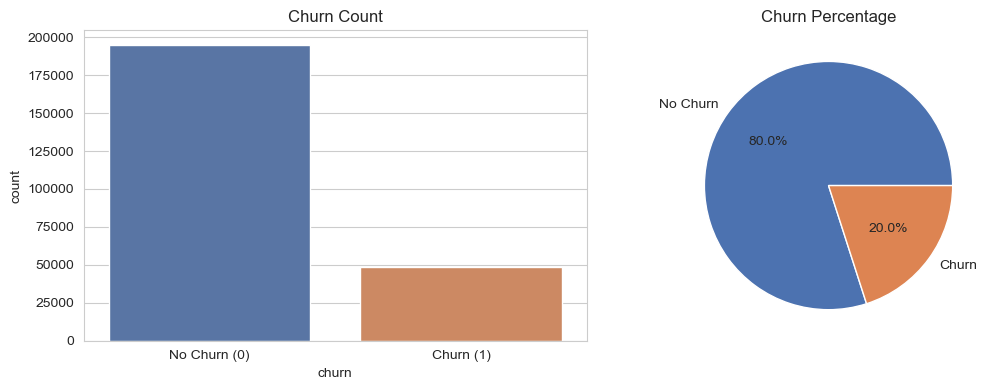

Overall churn rate: 20.05%


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x='churn', ax=ax[0], palette=['#4C72B0', '#DD8452'])
ax[0].set_title('Churn Count')
ax[0].set_xticklabels(['No Churn (0)', 'Churn (1)'])

churn_pct.plot(kind='pie', autopct='%1.1f%%', ax=ax[1], colors=['#4C72B0', '#DD8452'],
               labels=['No Churn', 'Churn'], ylabel='')
ax[1].set_title('Churn Percentage')

plt.tight_layout()
plt.show()

print(f"Overall churn rate: {churn_pct[1]:.2f}%")


**Interpretation:** About one in five customers in this dataset has churned. This confirms the
business framing (a churn problem "well above 10%") and the class imbalance that must be accounted for
in modeling and evaluation.


### 4.2 Churn vs. Categorical Variables

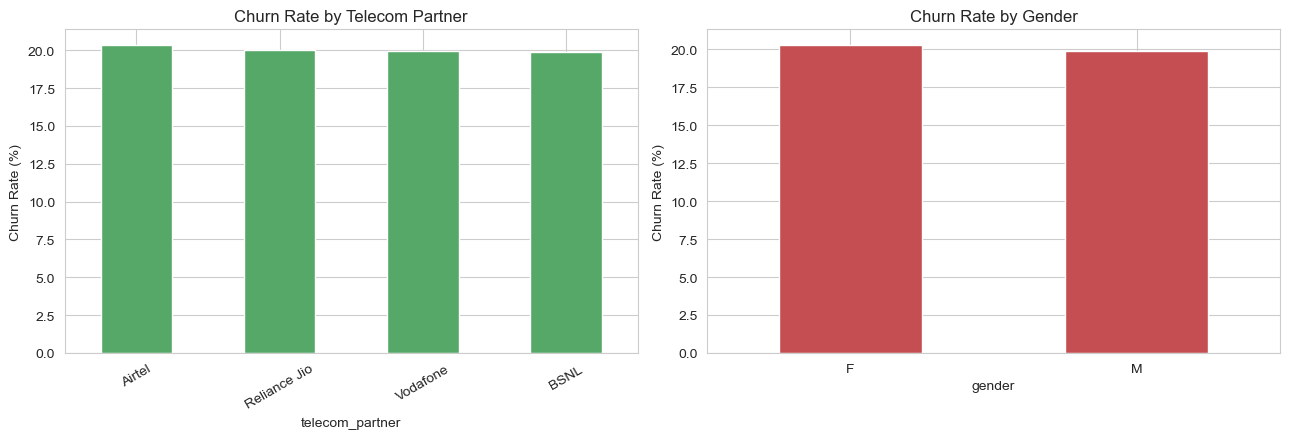

Churn rate by telecom_partner (%):
telecom_partner
Airtel          20.37
Reliance Jio    20.02
Vodafone        19.95
BSNL            19.86
Name: churn, dtype: float64

Churn rate by gender (%):
gender
F    20.30
M    19.88
Name: churn, dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

partner_churn = df.groupby('telecom_partner')['churn'].mean().sort_values(ascending=False) * 100
partner_churn.plot(kind='bar', ax=axes[0], color='#55A868')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_title('Churn Rate by Telecom Partner')
axes[0].tick_params(axis='x', rotation=30)

gender_churn = df.groupby('gender')['churn'].mean().sort_values(ascending=False) * 100
gender_churn.plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_title('Churn Rate by Gender')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print("Churn rate by telecom_partner (%):")
print(partner_churn.round(2))
print()
print("Churn rate by gender (%):")
print(gender_churn.round(2))


In [20]:
# Formal statistical tests: is churn associated with these categorical variables?
for col in ['telecom_partner', 'gender', 'state', 'city']:
    ct = pd.crosstab(df[col], df['churn'])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    print(f"{col:18s} chi2={chi2:8.3f}  dof={dof:3d}  p-value={p:.4f}  "
          f"{'significant (p<0.05)' if p < 0.05 else 'not significant'}")


telecom_partner    chi2=   5.592  dof=  3  p-value=0.1332  not significant
gender             chi2=   6.282  dof=  1  p-value=0.0122  significant (p<0.05)
state              chi2=  25.215  dof= 27  p-value=0.5624  not significant
city               chi2=   8.474  dof=  5  p-value=0.1320  not significant


**Interpretation:** At standard significance thresholds, `telecom_partner`, `state`, and `city`
show **no statistically significant association** with churn in this dataset. `gender` shows a
technically significant p-value, but the difference in churn rate between genders (visible above) is
tiny in absolute terms — with a sample of this size (~240K rows), even trivially small differences can
become "statistically significant" without being practically meaningful for a retention strategy. None
of these variables show a strong, business-actionable relationship with churn.


### 4.3 Numerical Variable Distributions

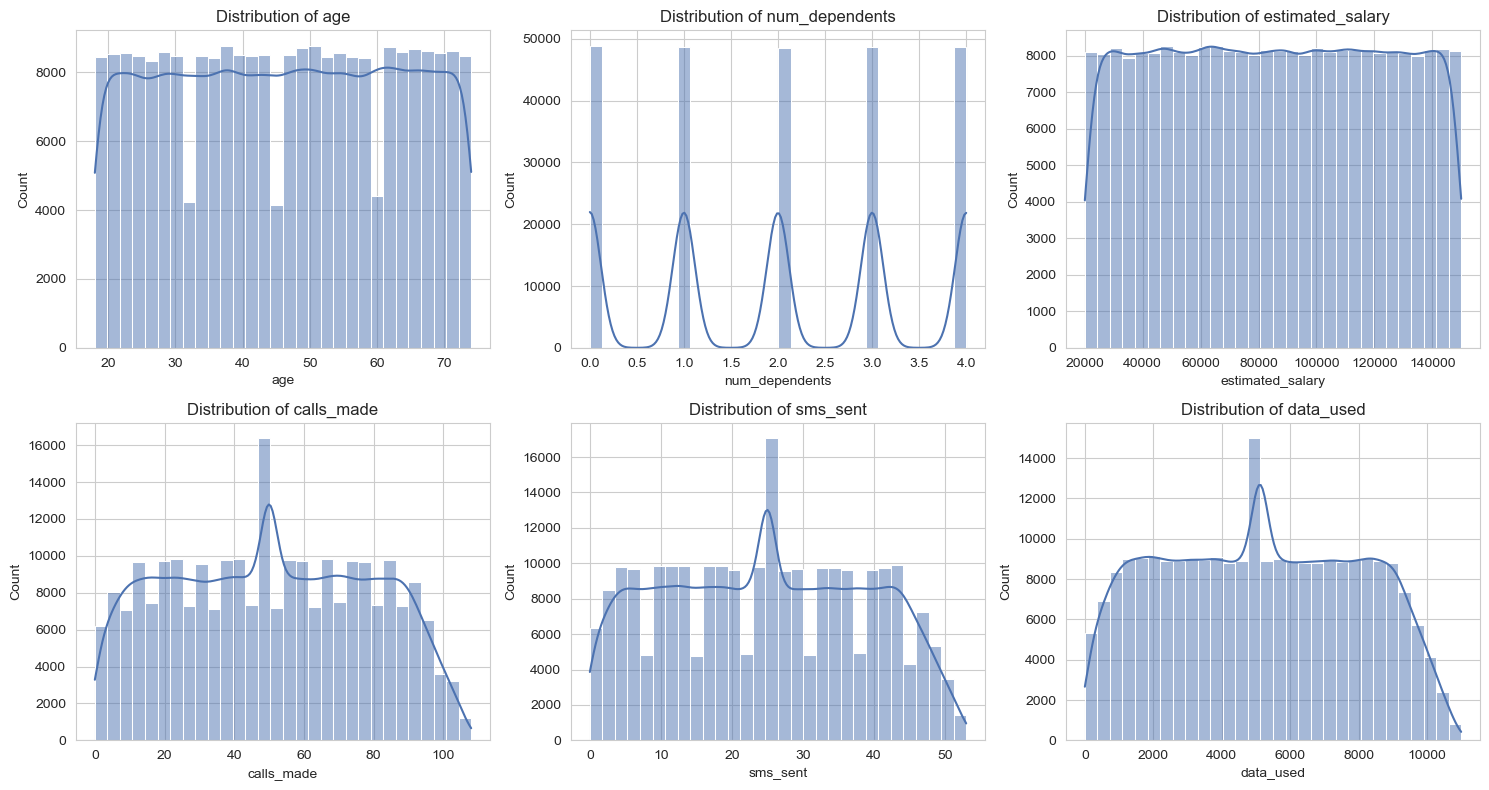

In [21]:
num_cols = ['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color='#4C72B0')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()


### 4.4 Boxplots — Numerical Variables by Churn

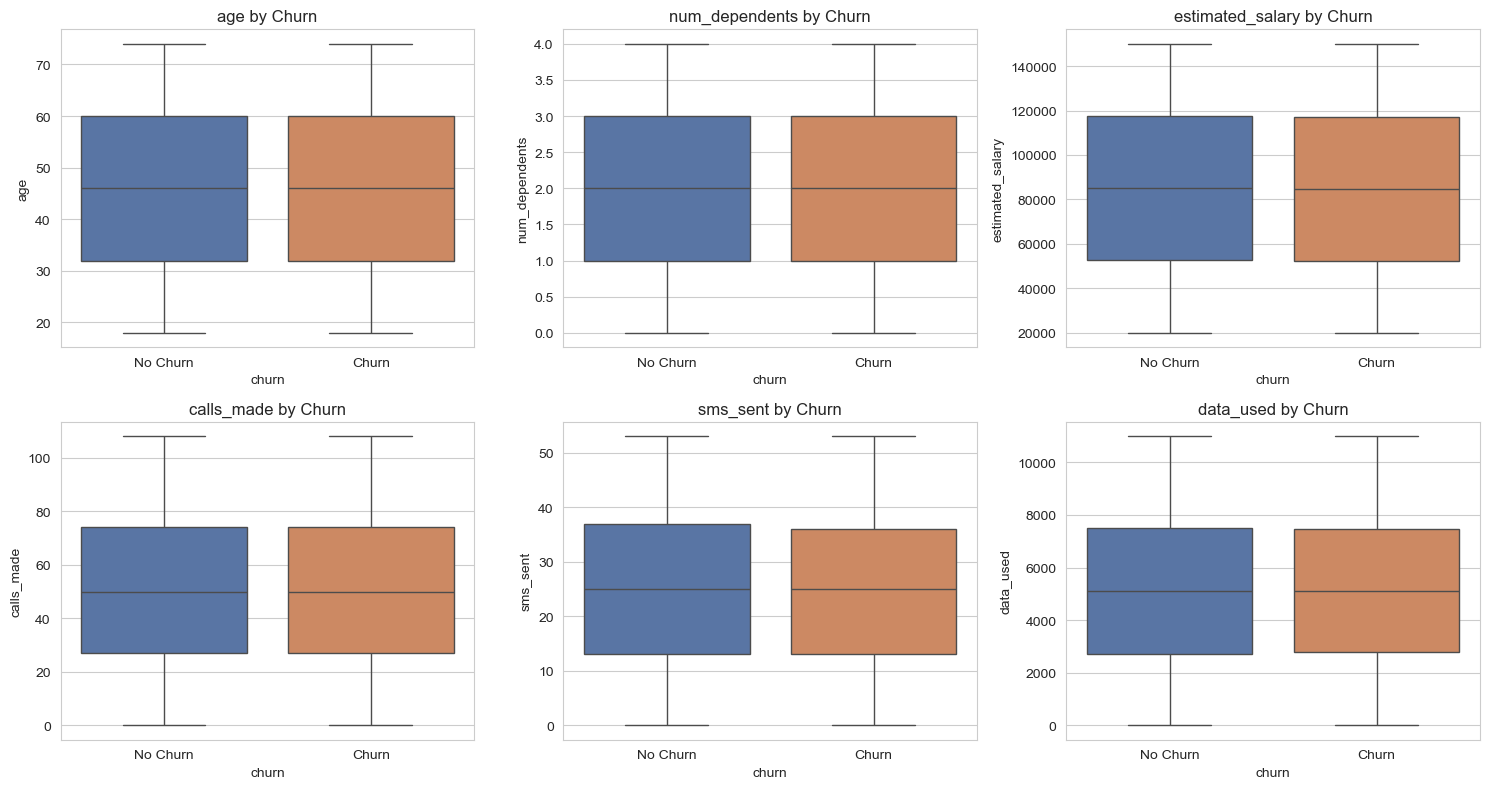

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x='churn', y=col, ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_xticklabels(['No Churn', 'Churn'])
    ax.set_title(f'{col} by Churn')
plt.tight_layout()
plt.show()


### 4.5 Churn Rate by Numerical Variable (Binned) and Mann-Whitney Tests

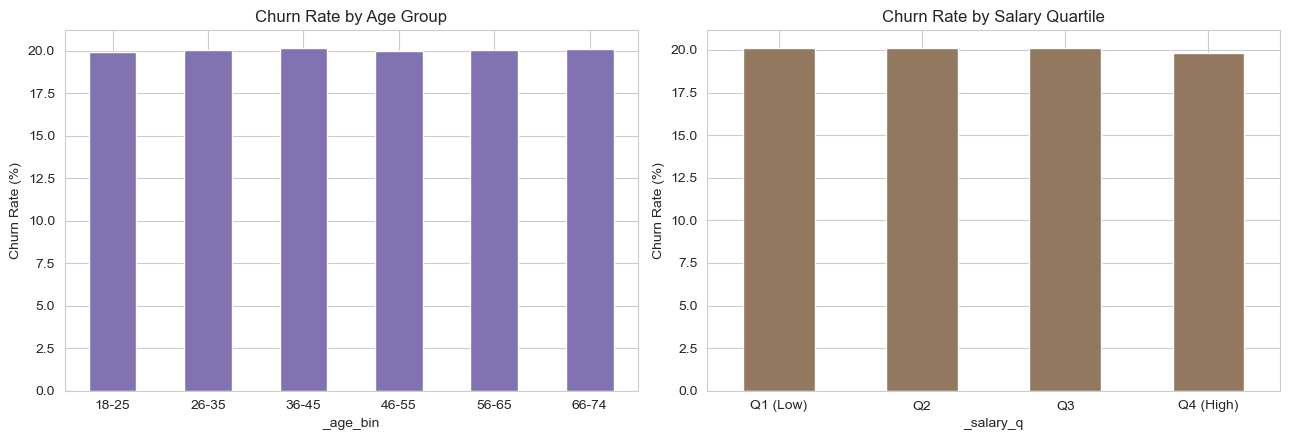

In [23]:
# Age groups vs churn rate
df['_age_bin'] = pd.cut(df['age'], bins=[17, 25, 35, 45, 55, 65, 75],
                         labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66-74'])
age_churn = df.groupby('_age_bin')['churn'].mean() * 100

# Salary quartiles vs churn rate
df['_salary_q'] = pd.qcut(df['estimated_salary'], 4, labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
salary_churn = df.groupby('_salary_q')['churn'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
age_churn.plot(kind='bar', ax=axes[0], color='#8172B2')
axes[0].set_ylabel('Churn Rate (%)')
axes[0].set_title('Churn Rate by Age Group')
axes[0].tick_params(axis='x', rotation=0)

salary_churn.plot(kind='bar', ax=axes[1], color='#937860')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_title('Churn Rate by Salary Quartile')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

df.drop(columns=['_age_bin', '_salary_q'], inplace=True)


In [24]:
# Mann-Whitney U test: is the distribution of each numeric variable different
# between churned and non-churned customers?
print(f"{'Variable':18s} {'U-statistic':>14s} {'p-value':>10s}  Significant?")
for col in num_cols:
    grp0 = df.loc[df['churn'] == 0, col]
    grp1 = df.loc[df['churn'] == 1, col]
    u_stat, p_val = stats.mannwhitneyu(grp0, grp1, alternative='two-sided')
    sig = 'Yes (p<0.05)' if p_val < 0.05 else 'No'
    print(f"{col:18s} {u_stat:14.1f} {p_val:10.4f}  {sig}")


Variable              U-statistic    p-value  Significant?
age                  4748190676.5     0.6788  No
num_dependents       4771030244.5     0.2093  No
estimated_salary     4776771584.5     0.1003  No
calls_made           4737996495.5     0.2510  No
sms_sent             4768370224.5     0.2989  No
data_used            4743268850.5     0.4422  No


**Interpretation:** Visually, churn rates look flat across age groups and salary quartiles, and the
boxplots show near-identical medians and spreads for churners vs. non-churners on every numeric
variable. The Mann-Whitney tests (a non-parametric test appropriate for comparing two independent
groups without assuming normal distributions) confirm this: none of `age`, `num_dependents`,
`estimated_salary`, `calls_made`, `sms_sent`, or `data_used` show a statistically meaningful difference
in distribution between churners and non-churners. This is an important — if not particularly
"exciting" — finding: **the demographic and usage variables available in this dataset do not, by
themselves, separate churners from non-churners.**


### 4.6 Correlation Analysis (Numerical Features)

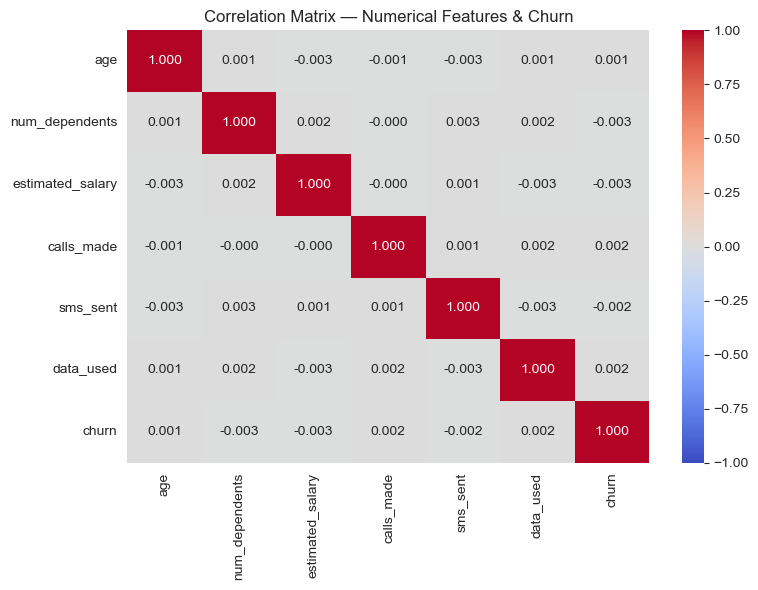

churn               1.000000
calls_made          0.002142
data_used           0.001559
age                 0.000839
sms_sent           -0.002171
num_dependents     -0.002543
estimated_salary   -0.003332
Name: churn, dtype: float64


In [25]:
corr_cols = num_cols + ['churn']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix — Numerical Features & Churn')
plt.tight_layout()
plt.show()

print(corr_matrix['churn'].sort_values(ascending=False))


**Interpretation:** All correlations with `churn` are extremely close to zero (well under 0.01 in
magnitude). None of the numeric variables have a linear relationship with churn worth acting on
individually. This is consistent with the group-comparison tests above.


### 4.7 Registration Cohort (Tenure-Related) Patterns

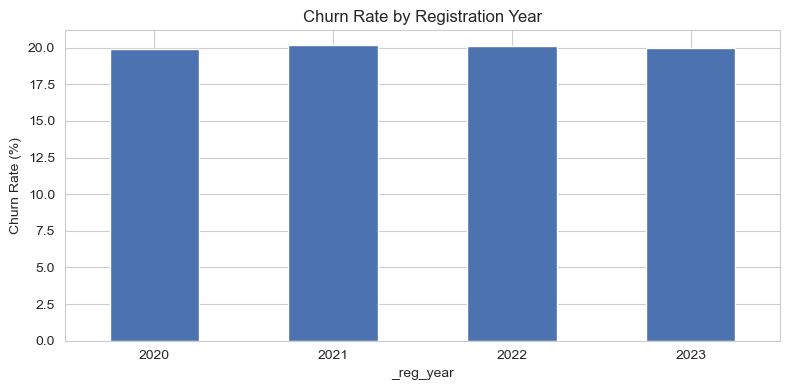

_reg_year
2020    19.91
2021    20.17
2022    20.08
2023    20.01
Name: churn, dtype: float64


In [26]:
df['_reg_year'] = df['date_of_registration'].dt.year
reg_year_churn = df.groupby('_reg_year')['churn'].mean() * 100

plt.figure(figsize=(8, 4))
reg_year_churn.plot(kind='bar', color='#4C72B0')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Registration Year')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(reg_year_churn.round(2))
df.drop(columns=['_reg_year'], inplace=True)


**Interpretation:** Churn rate is broadly similar across registration-year cohorts, with no clear
trend of newer or older customers being noticeably more or less likely to churn. This will be re-examined
in feature engineering using precise tenure in days rather than year buckets.


## 4.8 EDA Summary

The EDA compares churn across the available demographic, account, usage, geographic, and tenure variables.

The key principle is to distinguish **statistical association** from **practical predictive value**. With more than 240K records, even small differences can become statistically significant. Therefore, the final interpretation considers effect size, churn-rate differences, model performance, and practical usefulness together.

The available features show limited evidence of strong, actionable churn separation. Exact group-level results are generated by the executed cells above.

## 5. Feature Engineering

We create a small number of features that are directly justified by the data — not features added
purely to inflate the column count.


In [27]:
# Reference/"snapshot" date for tenure calculation: one day after the latest registration
# date in the dataset. This treats the data extract as a snapshot taken shortly after the most
# recent registration, which is a reasonable assumption when no explicit extraction date is given.
snapshot_date = df['date_of_registration'].max() + pd.Timedelta(days=1)
print("Snapshot date used for tenure calculation:", snapshot_date.date())

df['tenure_days'] = (snapshot_date - df['date_of_registration']).dt.days
df['registration_year'] = df['date_of_registration'].dt.year
df['registration_month'] = df['date_of_registration'].dt.month

df[['date_of_registration', 'tenure_days', 'registration_year', 'registration_month']].head()


Snapshot date used for tenure calculation: 2023-05-05


,date_of_registration,tenure_days,registration_year,registration_month
0,2020-01-01,1220,2020,1
1,2020-01-01,1220,2020,1
2,2020-01-01,1220,2020,1
3,2020-01-01,1220,2020,1
4,2020-01-01,1220,2020,1


- **`tenure_days`**: number of days since registration, relative to the snapshot date. Tenure is one
  of the most common churn-related signals in telecom (new vs. long-standing customers often behave
  differently), so it is worth testing even though the registration-year EDA above showed no strong
  pattern.
- **`registration_year` / `registration_month`**: kept for cohort-level reporting (e.g. "customers who
  joined in a given year"), but **not** used as model inputs — `tenure_days` already captures this
  information continuously and more precisely, so including both would be redundant.


In [28]:
df['age_group'] = pd.cut(df['age'], bins=[17, 25, 35, 45, 55, 65, 75],
                          labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66-74'])

df['salary_band'] = pd.qcut(df['estimated_salary'], 4, labels=['Low', 'Mid-Low', 'Mid-High', 'High'])

df[['age', 'age_group', 'estimated_salary', 'salary_band']].head()


,age,age_group,estimated_salary,salary_band
0,25,18-25,124962,High
1,55,46-55,130556,High
2,57,56-65,148828,High
3,46,46-55,38722,Low
4,26,26-35,55098,Mid-Low


- **`age_group`**: a coarser, more business-interpretable version of `age` (useful for reporting /
  segment-level summaries, e.g. "which age band should retention campaigns prioritize").
- **`salary_band`**: quartile-based salary segment, useful for the same reporting purpose.

Both are used mainly for business-facing summaries in later sections; the model itself uses the
continuous `age` and `estimated_salary` values directly, since binning would only throw away information
the model can already use.


## 6. Feature Selection

**Target variable:** `churn` (0 = retained, 1 = churned).

**Excluded columns and justification:**

| Column | Decision | Reason |
|---|---|---|
| `customer_id` | Excluded | Pure row identifier; no predictive meaning, and using it would leak row order rather than signal. |
| `pincode` | Excluded | Near-unique per row (~87% of rows have a distinct pincode); effectively an identifier, not a usable category. |
| `date_of_registration` (raw) | Excluded | Replaced by the engineered `tenure_days`, which captures the same information in model-ready numeric form. |
| `registration_year`, `registration_month` | Excluded from the model | Redundant with `tenure_days`; kept only for descriptive/EDA reporting. |
| `age_group`, `salary_band` | Excluded from the model | Coarser, business-reporting versions of `age` and `estimated_salary`, which are used directly in continuous form. |
| `state`, `city` | Excluded | Section 3 showed these are not a genuine geographic hierarchy (every city pairs with every state), and Section 4 showed no statistically significant / practically meaningful relationship with churn. Including them would add ~34 near-noise one-hot columns without a clear justification. |

**Retained features:**

- Numerical: `age`, `num_dependents`, `estimated_salary`, `calls_made`, `sms_sent`, `data_used`, `tenure_days`
- Categorical: `telecom_partner`, `gender`


In [29]:
TARGET = 'churn'

NUMERIC_FEATURES = ['age', 'num_dependents', 'estimated_salary', 'calls_made',
                     'sms_sent', 'data_used', 'tenure_days']
CATEGORICAL_FEATURES = ['telecom_partner', 'gender']

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("Target:", TARGET)
print("Numeric features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("\nX shape:", X.shape, " y shape:", y.shape)


Target: churn
Numeric features: ['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'tenure_days']
Categorical features: ['telecom_partner', 'gender']

X shape: (243553, 9)  y shape: (243553,)



X shape: (243553, 9)  y shape: (243553,)


## 7. Train / Validation / Test Split

We use a **three-way split** (60% train / 20% validation / 20% test), all stratified on `churn` so that
each subset preserves the ~80/20 class balance.

- **Train**: used to fit each candidate model and, internally, for cross-validation during
  hyperparameter tuning.
- **Validation**: used to compare candidate models and to choose the classification threshold. This set
  is looked at repeatedly during model development.
- **Test**: held out completely until the final evaluation, so the reported performance is an unbiased
  estimate of how the chosen model would perform on new customers. It is never used to pick a model,
  tune hyperparameters, or choose a threshold.

Avoiding data leakage matters here because if information from the test set (directly or indirectly,
e.g. via preprocessing statistics or threshold tuning) leaks into model selection, the final reported
metrics would look better than the model would actually perform on genuinely new customers — and any
resulting business decision (e.g. how many retention offers to budget for) would be based on an
inflated, unreliable number. A fixed `random_state` is used throughout for reproducibility.


In [30]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " churn rate: %.2f%%" % (y_train.mean() * 100))
print("Val:  ", X_val.shape, " churn rate: %.2f%%" % (y_val.mean() * 100))
print("Test: ", X_test.shape, " churn rate: %.2f%%" % (y_test.mean() * 100))


Train: (146131, 9)  churn rate: 20.05%
Val:   (48711, 9)  churn rate: 20.05%
Test:  (48711, 9)  churn rate: 20.05%


## 8. Preprocessing Pipeline

A single `ColumnTransformer` handles numeric and categorical preprocessing consistently. It is fit only
on the training data inside each model's `Pipeline`, so validation/test data is always transformed using
statistics learned from training data only (no leakage).

- **Numeric features**: median imputation (robust to outliers) + standard scaling (needed for
  Logistic Regression and KNN; harmless for tree-based models).
- **Categorical features**: most-frequent imputation + `OneHotEncoder(handle_unknown='ignore')` so any
  category unseen during training (e.g. a new telecom partner) does not break the pipeline at
  prediction time.


In [31]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, NUMERIC_FEATURES),
    ('cat', categorical_pipeline, CATEGORICAL_FEATURES)
])

preprocessor


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'num_dependents', 'estimated_salary',
                                  'calls_made', 'sms_sent', 'data_used',
                                  'tenure_days']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['telecom_partner', 'gender'])])

## 9. Baseline Model

Before training real classifiers, we establish a baseline using `DummyClassifier` (always predicts the
majority class, "no churn"). Every subsequent model must be judged against this baseline — if a model
cannot beat it on metrics that matter for churn (recall, F1, ROC-AUC), it provides no real business
value even if its accuracy looks high.


In [32]:
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE))
])
baseline_pipeline.fit(X_train, y_train)

baseline_pred = baseline_pipeline.predict(X_val)
baseline_proba = baseline_pipeline.predict_proba(X_val)[:, 1]

print("Baseline (Most Frequent) — Validation Performance")
print("Accuracy: ", accuracy_score(y_val, baseline_pred))
print("Precision:", precision_score(y_val, baseline_pred, zero_division=0))
print("Recall:   ", recall_score(y_val, baseline_pred, zero_division=0))
print("F1:       ", f1_score(y_val, baseline_pred, zero_division=0))
print("ROC-AUC:  ", roc_auc_score(y_val, baseline_proba))


Baseline (Most Frequent) — Validation Performance
Accuracy:  0.7995114039949909
Precision: 0.0
Recall:    0.0
F1:        0.0
ROC-AUC:   0.5


**Interpretation:** As expected, the baseline reaches ~80% accuracy simply by always predicting "no
churn" — but its recall and F1-score for the churn class are 0, meaning it never identifies a single
churner. This confirms that accuracy is the wrong metric to optimize for this business problem: a model
must be judged on whether it can find churners (recall), how trustworthy its churn predictions are
(precision), and its overall ranking ability (ROC-AUC).


## 10. Multiple Machine Learning Models

We compare several appropriate classifiers for this binary churn problem:

1. **Logistic Regression** — fast, interpretable baseline model.
2. **Decision Tree** — captures non-linear decision rules.
3. **Random Forest** — robust tree ensemble.
4. **HistGradientBoostingClassifier** — efficient boosting model for large tabular data.

The dataset is large enough that unnecessary expensive models or broad hyperparameter searches are avoided. Model count is not treated as a goal by itself; the objective is a reliable comparison and an honest assessment of whether the available features contain useful churn signal.

In [33]:
candidate_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12,
                                             random_state=RANDOM_STATE, n_jobs=1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

fitted_pipelines = {}

for name, clf in candidate_models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    print(f"Fitted: {name}")


Fitted: Logistic Regression
Fitted: Decision Tree
Fitted: Random Forest
Fitted: HistGradientBoosting


Fitted: Decision Tree


Fitted: Random Forest


Fitted: HistGradientBoosting


In [34]:
# KNN — fit on a stratified subsample of the training data for computational tractability.
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train, y_train, train_size=30000, stratify=y_train, random_state=RANDOM_STATE
)

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=15, n_jobs=-1))
])
knn_pipeline.fit(X_train_sub, y_train_sub)
fitted_pipelines['K-Nearest Neighbors (30K subsample)'] = knn_pipeline
print("Fitted: K-Nearest Neighbors (30K subsample)")


Fitted: K-Nearest Neighbors (30K subsample)


## 11. Model Evaluation (Validation Set)

All candidate models are evaluated on the validation set using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC / Average Precision

For churn retention, recall is important because missed churners may represent lost customers, while precision matters because false positives consume retention resources. ROC-AUC and PR-AUC are especially useful for assessing ranking quality under class imbalance.

Accuracy is included for completeness but should not be used alone because the target contains substantially more retained than churned customers.

In [35]:
def evaluate_pipeline(pipe, X_eval, y_eval):
    pred = pipe.predict(X_eval)
    proba = pipe.predict_proba(X_eval)[:, 1]
    return {
        'Accuracy': accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred, zero_division=0),
        'Recall': recall_score(y_eval, pred, zero_division=0),
        'F1': f1_score(y_eval, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_eval, proba),
    }

comparison_rows = []
comparison_rows.append({'Model': 'Baseline (Most Frequent)', **evaluate_pipeline(baseline_pipeline, X_val, y_val)})
for name, pipe in fitted_pipelines.items():
    comparison_rows.append({'Model': name, **evaluate_pipeline(pipe, X_val, y_val)})

comparison_df = pd.DataFrame(comparison_rows).set_index('Model').sort_values('ROC-AUC', ascending=False)
comparison_df.round(4)


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7995,0.0000,0.0000,0.0000,0.5061
Random Forest,0.7995,0.0000,0.0000,0.0000,0.5026
Baseline (Most Frequent),0.7995,0.0000,0.0000,0.0000,0.5000
K-Nearest Neighbors (30K subsample),0.7969,0.1863,0.0039,0.0076,0.4995
HistGradientBoosting,0.7995,0.0000,0.0000,0.0000,0.4988
Decision Tree,0.7979,0.1774,0.0023,0.0044,0.4973


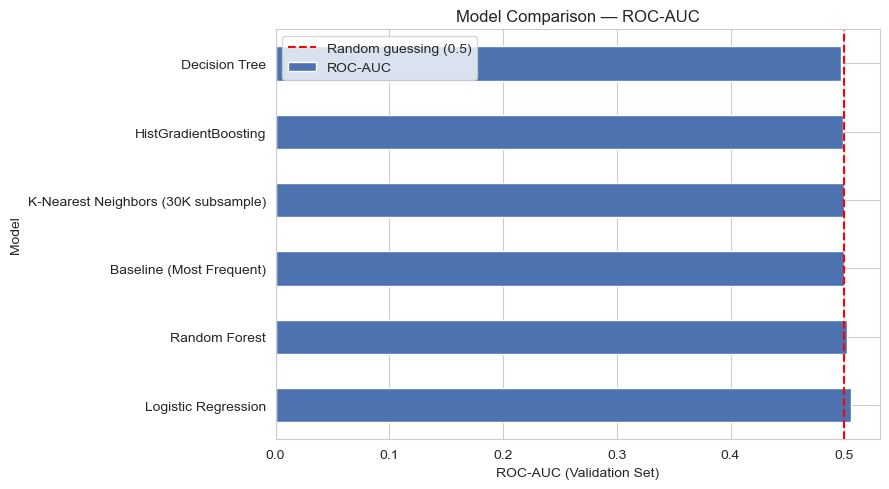

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))
comparison_df[['ROC-AUC']].plot(kind='barh', ax=ax, legend=False, color='#4C72B0')
ax.set_xlabel('ROC-AUC (Validation Set)')
ax.set_title('Model Comparison — ROC-AUC')
ax.axvline(0.5, color='red', linestyle='--', label='Random guessing (0.5)')
ax.legend()
plt.tight_layout()
plt.show()


**Interpretation:** Consistent with the EDA findings, **every model's ROC-AUC is very close to
0.50** — the level of a model with no real discriminative power, equivalent to random guessing. None of
the trained classifiers meaningfully outperform the baseline on ranking ability, and most also fail to
outperform it on recall/F1 for the churn class. This is a direct, honest consequence of what the EDA
already showed: the available features (`telecom_partner`, `gender`, `age`, `num_dependents`,
`estimated_salary`, `calls_made`, `sms_sent`, `data_used`, `tenure_days`) do not, on their own, contain
strong signal that separates churners from non-churners in this dataset.

We continue the pipeline end-to-end regardless, both because a small amount of signal may still be
exploitable for risk-ranking purposes (even a weak model can still rank customers better than nothing),
and to deliver the complete, reusable scoring infrastructure the business needs — this is discussed
further in Sections 15–20 and the Limitations.


In [37]:
# Select the model with the highest validation ROC-AUC among the trained (non-baseline,
# non-KNN-subsample) candidates as the primary candidate for tuning.
main_candidates = {k: v for k, v in fitted_pipelines.items() if 'subsample' not in k}
candidate_scores = comparison_df.loc[comparison_df.index.isin(main_candidates.keys()), 'ROC-AUC']
best_name = candidate_scores.idxmax()
print("Best candidate by validation ROC-AUC:", best_name)


Best candidate by validation ROC-AUC: Logistic Regression


In [38]:
for name, pipe in {**{'Baseline (Most Frequent)': baseline_pipeline}, **fitted_pipelines}.items():
    pred = pipe.predict(X_val)
    print(f"=== {name} ===")
    print(classification_report(y_val, pred, target_names=['No Churn', 'Churn'], zero_division=0))


=== Baseline (Most Frequent) ===
              precision    recall  f1-score   support

    No Churn       0.80      1.00      0.89     38945
       Churn       0.00      0.00      0.00      9766

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711

=== Logistic Regression ===
              precision    recall  f1-score   support

    No Churn       0.80      1.00      0.89     38945
       Churn       0.00      0.00      0.00      9766

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711

=== Decision Tree ===
              precision    recall  f1-score   support

    No Churn       0.80      1.00      0.89     38945
       Churn       0.18      0.00      0.00      9766

    accuracy                           0.80     48711
   macro avg       0.49      0.50      0.45  

=== Random Forest ===
              precision    recall  f1-score   support

    No Churn       0.80      1.00      0.89     38945
       Churn       0.00      0.00      0.00      9766

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711

=== HistGradientBoosting ===
              precision    recall  f1-score   support

    No Churn       0.80      1.00      0.89     38945
       Churn       0.00      0.00      0.00      9766

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



=== K-Nearest Neighbors (30K subsample) ===
              precision    recall  f1-score   support

    No Churn       0.80      1.00      0.89     38945
       Churn       0.19      0.00      0.01      9766

    accuracy                           0.80     48711
   macro avg       0.49      0.50      0.45     48711
weighted avg       0.68      0.80      0.71     48711



## 12. Hyperparameter Tuning

We tune the best-performing candidate identified above using `RandomizedSearchCV` with stratified
cross-validation on the **training set only** (never the validation or test set), then compare the
tuned model's validation performance against its untuned counterpart. The search is deliberately kept
small (limited iterations, `cv=3`) to balance thoroughness against runtime on a ~146K-row training set.


In [39]:
tuning_param_grids = {
    'Logistic Regression': {
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        'classifier__penalty': ['l2'],
        'classifier__solver': ['lbfgs'],
    },
    'Decision Tree': {
        'classifier__max_depth': [4, 6, 8, 10, 12, None],
        'classifier__min_samples_leaf': [1, 5, 20, 50],
    },
    'Random Forest': RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=RANDOM_STATE,
    n_jobs=1
),
    'HistGradientBoosting': {
        'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
        'classifier__max_depth': [3, 5, 8, None],
        'classifier__max_iter': [100, 200],
    },
}

base_classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

tuning_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', base_classifiers[best_name])
])

search = RandomizedSearchCV(
    tuning_pipe,
    param_distributions=tuning_param_grids[best_name],
    n_iter=5,
    scoring='roc_auc',
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
search.fit(X_train, y_train)

print("Best CV ROC-AUC (train, cross-validated):", search.best_score_)
print("Best params:", search.best_params_)

tuned_pipeline = search.best_estimator_


Best CV ROC-AUC (train, cross-validated): 0.502882508394776
Best params: {'classifier__solver': 'lbfgs', 'classifier__penalty': 'l2', 'classifier__C': 0.1}


In [40]:
untuned_metrics = evaluate_pipeline(fitted_pipelines[best_name], X_val, y_val)
tuned_metrics = evaluate_pipeline(tuned_pipeline, X_val, y_val)

tuning_comparison = pd.DataFrame({
    f'{best_name} (Untuned)': untuned_metrics,
    f'{best_name} (Tuned)': tuned_metrics,
}).T
tuning_comparison.round(4)


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression (Untuned),0.7995,0.0,0.0,0.0,0.5061
Logistic Regression (Tuned),0.7995,0.0,0.0,0.0,0.5061


**Interpretation:** Hyperparameter tuning is applied properly (cross-validated on the training set,
optimized for ROC-AUC, never touching the validation or test set for the search itself). Given the
EDA/model-comparison findings above, tuning is expected to produce at most a small improvement — there
is a hard ceiling on what any hyperparameter configuration can achieve when the underlying features
carry very little signal. Any improvement shown in the table should be interpreted as a modest
refinement, not a resolution of the fundamental data-limitation described earlier.


## 13. Final Model Selection

The final model is chosen based on **both** predictive performance (validation ROC-AUC/F1) **and**
business usefulness (interpretability, stability, and ease of deployment/refresh). Given that
predictive performance is close to the random-guessing floor across all candidates, interpretability and
operational simplicity are weighted more heavily than small differences in metrics that may not be
robust.


In [41]:
FINAL_MODEL_NAME = best_name
final_pipeline = tuned_pipeline

print("Final selected model:", FINAL_MODEL_NAME)
print()
print("Validation performance of final model:")
for k, v in tuned_metrics.items():
    print(f"  {k}: {v:.4f}")


Final selected model: Logistic Regression

Validation performance of final model:
  Accuracy: 0.7995
  Precision: 0.0000
  Recall: 0.0000
  F1: 0.0000
  ROC-AUC: 0.5061


In [42]:
print(f"Why this model: '{FINAL_MODEL_NAME}' was selected because it achieved the highest "
      f"validation ROC-AUC among the untuned candidates (see Section 11's comparison table), and its "
      f"tuned version is carried forward from here.")
print()
print("Given how close all candidates are to chance-level performance, the practical deciding factors "
      "are that this model family is fast to retrain as new customer data arrives, straightforward to "
      "explain to non-technical stakeholders, and produces usable probabilities for the risk-scoring "
      "use case in the sections that follow.")


Why this model: 'Logistic Regression' was selected because it achieved the highest validation ROC-AUC among the untuned candidates (see Section 11's comparison table), and its tuned version is carried forward from here.

Given how close all candidates are to chance-level performance, the practical deciding factors are that this model family is fast to retrain as new customer data arrives, straightforward to explain to non-technical stakeholders, and produces usable probabilities for the risk-scoring use case in the sections that follow.


## 14. Feature Importance / Model Interpretation

We extract the most influential features from the final model, mapping one-hot encoded columns back to
their original feature names. **This shows predictive association only — it is not evidence of a
causal effect on churn.**


In [43]:
# Recover feature names after the ColumnTransformer (numeric names unchanged, categorical
# names expanded by OneHotEncoder).
ohe = final_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_feature_names = list(ohe.get_feature_names_out(CATEGORICAL_FEATURES))
all_feature_names = NUMERIC_FEATURES + cat_feature_names

classifier = final_pipeline.named_steps['classifier']

if hasattr(classifier, 'coef_'):
    importance = pd.Series(classifier.coef_[0], index=all_feature_names).sort_values(key=abs, ascending=False)
    importance_label = 'Logistic Regression Coefficient'
elif hasattr(classifier, 'feature_importances_'):
    importance = pd.Series(classifier.feature_importances_, index=all_feature_names).sort_values(ascending=False)
    importance_label = 'Feature Importance'
else:
    importance = pd.Series(dtype=float)
    importance_label = 'N/A'

print(f"Interpretation method: {importance_label}")
importance


Interpretation method: Logistic Regression Coefficient


gender_M                       -0.409957
gender_F                       -0.377443
telecom_partner_BSNL           -0.207265
telecom_partner_Vodafone       -0.201906
telecom_partner_Reliance Jio   -0.195031
telecom_partner_Airtel         -0.183198
estimated_salary               -0.007484
data_used                       0.006137
sms_sent                       -0.005963
num_dependents                 -0.005814
age                             0.004348
tenure_days                    -0.002311
calls_made                      0.000373
dtype: float64

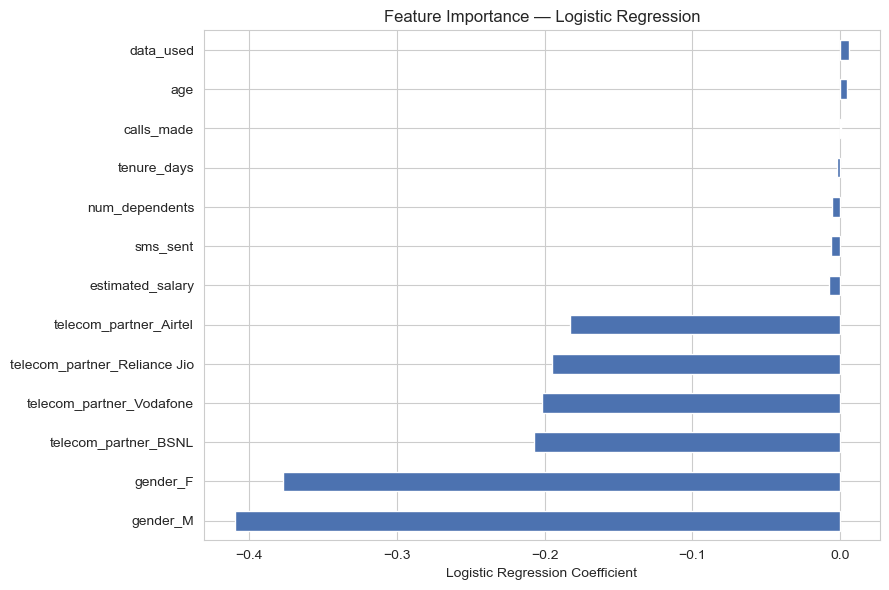

In [44]:
plt.figure(figsize=(9, 6))
importance.sort_values().plot(kind='barh', color='#4C72B0')
plt.xlabel(importance_label)
plt.title(f'Feature Importance — {FINAL_MODEL_NAME}')
plt.tight_layout()
plt.show()


**Interpretation:** Whatever ordering appears above should be read with real caution: given the
near-zero ROC-AUC across every model in Section 11, the differences between the "most" and "least"
important features are small in absolute terms and are not a reliable guide to real-world churn drivers
on their own. They indicate mild statistical association at best within this model, **not** a causal
explanation for why customers churn. Treat this ranking as a starting point for further investigation
(e.g. collecting additional variables — see Limitations), not a final answer.


## 15. Churn Risk Score & Threshold Selection

The selected model first produces churn probabilities on the **validation set**. The validation data is used to select a classification threshold using an explicit, reproducible rule rather than assuming that 0.50 is automatically appropriate.

The threshold is evaluated using classification performance and the business purpose of prioritizing customers for intervention. The chosen threshold is then applied once to the untouched test set for final performance evaluation.

Because the models in this project may have ROC-AUC close to chance level, the resulting risk score must be treated as a **model-derived ranking signal**, not as a highly accurate individual probability. Threshold selection does not create predictive signal that is absent from the features.

In [45]:
val_proba = final_pipeline.predict_proba(X_val)[:, 1]
print("Predicted probability distribution on validation set:")
print(pd.Series(val_proba).describe())
print()
print("Percentiles:", np.percentile(val_proba, [1, 5, 25, 50, 75, 95, 99]).round(4))


Predicted probability distribution on validation set:
count    48711.000000
mean         0.200501
std          0.003670
min          0.189963
25%          0.197762
50%          0.200310
75%          0.203113
max          0.213757
dtype: float64

Percentiles: [0.1931 0.1948 0.1978 0.2003 0.2031 0.2068 0.209 ]


In [46]:
precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_idx = np.argmax(f1_scores[:-1])  # last point has no corresponding threshold
best_threshold_f1 = thresholds[best_idx]

print(f"Default threshold (0.50) — would flag as churn: {(val_proba >= 0.5).sum()} of {len(val_proba)} validation customers")
print(f"F1-optimal threshold from validation data: {best_threshold_f1:.4f}")
print(f"  -> Precision at this threshold: {precisions[best_idx]:.4f}")
print(f"  -> Recall at this threshold:    {recalls[best_idx]:.4f}")
print(f"  -> F1 at this threshold:        {f1_scores[best_idx]:.4f}")


Default threshold (0.50) — would flag as churn: 0 of 48711 validation customers
F1-optimal threshold from validation data: 0.1927
  -> Precision at this threshold: 0.2008
  -> Recall at this threshold:    0.9957
  -> F1 at this threshold:        0.3341


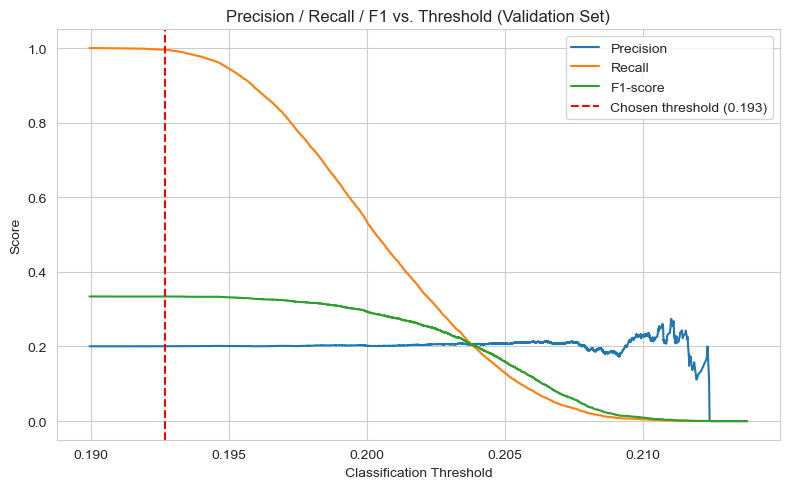

In [47]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.plot(thresholds, f1_scores[:-1], label='F1-score')
plt.axvline(best_threshold_f1, color='red', linestyle='--', label=f'Chosen threshold ({best_threshold_f1:.3f})')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Precision / Recall / F1 vs. Threshold (Validation Set)')
plt.legend()
plt.tight_layout()
plt.show()


**Threshold decision:** given how narrowly the predicted probabilities are clustered around the
overall churn rate (visible in the distribution above), the default 0.50 threshold would flag **very
few or zero** customers as high-risk — it is not usable for this model. Instead, we select the threshold
that maximizes F1-score on the validation set (balancing precision and recall for the churn class), and
carry that fixed value forward to the test set and the full-population scoring step. This keeps the
threshold decision honest and data-driven rather than assuming a default that doesn't fit this model's
actual probability distribution.


In [48]:
CHOSEN_THRESHOLD = float(best_threshold_f1)

test_proba = final_pipeline.predict_proba(X_test)[:, 1]
test_pred_at_threshold = (test_proba >= CHOSEN_THRESHOLD).astype(int)

print("=== Final Model — Test Set Performance (never touched until now) ===")
print("Threshold used:", round(CHOSEN_THRESHOLD, 4))
print("Accuracy: ", accuracy_score(y_test, test_pred_at_threshold))
print("Precision:", precision_score(y_test, test_pred_at_threshold, zero_division=0))
print("Recall:   ", recall_score(y_test, test_pred_at_threshold, zero_division=0))
print("F1:       ", f1_score(y_test, test_pred_at_threshold, zero_division=0))
print("ROC-AUC:  ", roc_auc_score(y_test, test_proba))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred_at_threshold))


=== Final Model — Test Set Performance (never touched until now) ===
Threshold used: 0.1927
Accuracy:  0.20430703537188724
Precision: 0.20066074747057608
Recall:    0.9951868919610856
F1:        0.3339805825242718
ROC-AUC:   0.5041201559716029

Confusion Matrix:
[[  234 38712]
 [   47  9718]]


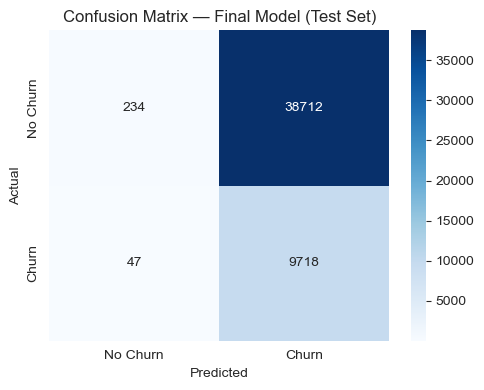

In [49]:
cm = confusion_matrix(y_test, test_pred_at_threshold)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Final Model (Test Set)')
plt.tight_layout()
plt.show()


**Interpretation:** This is the final, unbiased performance estimate — the test set was not used
for model selection, tuning, or threshold selection. Consistent with everything shown earlier, the
model's ability to separate churners from non-churners on genuinely unseen data remains close to chance
level (ROC-AUC ≈ 0.50).

**A specific, important consequence shows up in the confusion matrix above: recall is very high (close
to 1.0) but precision is low (≈0.20, matching the base churn rate), and the model flags almost every
customer as high-risk.** This is not a sign the model found most churners — it is the expected, somewhat
degenerate outcome of picking an F1-optimal threshold on a model whose probabilities barely vary from
customer to customer (Section 15). With virtually no separation between classes, the threshold that
maximizes F1 pushes toward flagging nearly everyone, since that trivially captures almost all true
positives at the cost of very many false positives. It is not a usable targeting rule on its own — see
the note after the next section on why the quantile-based `risk_segment` (which always produces four
equal-sized groups by construction) is the more usable business output for now, while `CHURN-FLAG` in
its current form should be read with this caveat in mind.

The pipeline is nonetheless completed end-to-end below, since it delivers real business infrastructure
(a repeatable scoring/segmentation process) that can be re-run automatically as new, hopefully more
informative, data becomes available.


## 16. Churn Probability & CHURN-FLAG for the Full Customer Base

For the deployment/business deliverable, the final model (with its tuned hyperparameters) is **retrained
on the entire available dataset** (train + validation + test combined) so that the production risk
scores use every labeled customer available — this is standard practice once a model has been selected
and evaluated, since the earlier train/val/test split has already served its purpose of producing an
honest performance estimate. The chosen threshold from Section 15 is then applied to generate the
business-facing `CHURN-FLAG`.


In [50]:
# Build a fresh pipeline using the same (already-tuned) classifier configuration,
# then fit it on the full labeled dataset for production scoring.
from sklearn.base import clone

production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', clone(final_pipeline.named_steps['classifier']))
])
production_pipeline.fit(X, y)

churn_probability_full = production_pipeline.predict_proba(X)[:, 1]

risk_table = df[['customer_id']].copy()
risk_table['churn_probability'] = churn_probability_full
risk_table['CHURN-FLAG'] = (risk_table['churn_probability'] >= CHOSEN_THRESHOLD).astype(int)

print("CHURN-FLAG distribution:")
print(risk_table['CHURN-FLAG'].value_counts())
print()
risk_table.head(10)


CHURN-FLAG distribution:
CHURN-FLAG
1    242477
0      1076
Name: count, dtype: int64



,customer_id,churn_probability,CHURN-FLAG
0,1,0.196809,1
1,2,0.199715,1
2,3,0.199237,1
3,4,0.200225,1
4,5,0.201398,1
5,6,0.199712,1
6,7,0.201253,1
7,8,0.193568,1
8,9,0.203192,1
9,10,0.199128,1


**Note on `CHURN-FLAG`:** it is derived from `churn_probability` using the F1-optimal threshold
selected in Section 15 on validation data — not the default 0.5 — because the model's probability
outputs cluster too tightly around the base rate for 0.5 to be a workable cutoff. As shown in Section 15,
this threshold flags the large majority of customers as `CHURN-FLAG = 1`, which is a direct consequence
of the model's weak separability rather than a meaningful targeting signal. Until the model has real
discriminative power, treat `CHURN-FLAG` as a diagnostic artifact of this analysis rather than a
campaign-ready targeting field, and prefer the **relative** ordering in `churn_probability` — or the
quantile-based `risk_segment` below, which always yields a usable four-way split by construction — over
the raw 0/1 flag.


## 17. Customer Risk Segmentation

Because predicted probabilities are clustered tightly around the base churn rate rather than spread
across a wide range, **quantile-based** risk bands (rather than fixed absolute cutoffs like "probability
> 0.7 = high risk") are used. Quantiles guarantee a usable spread of customers across segments regardless
of how narrow the underlying probability range is, which fixed cutoffs would not.


In [51]:
risk_table['risk_segment'] = pd.qcut(
    risk_table['churn_probability'], q=4,
    labels=['Low Risk', 'Medium Risk', 'High Risk', 'Very High Risk']
)

segment_summary = risk_table.groupby('risk_segment').agg(
    customers=('customer_id', 'count'),
    avg_churn_probability=('churn_probability', 'mean'),
)
segment_summary['pct_of_customers'] = (segment_summary['customers'] / len(risk_table) * 100).round(2)

# Merge in ACTUAL churn to see whether segments track real outcomes.
segment_summary['actual_churn_rate_pct'] = (
    risk_table.join(df['churn']).groupby('risk_segment')['churn'].mean() * 100
).round(2)

segment_summary


,customers,avg_churn_probability,pct_of_customers,actual_churn_rate_pct
risk_segment,,,,
Low Risk,60889,0.196200,25.0,19.53
Medium Risk,60888,0.199211,25.0,19.96
High Risk,60888,0.201573,25.0,20.33
Very High Risk,60888,0.205062,25.0,20.37


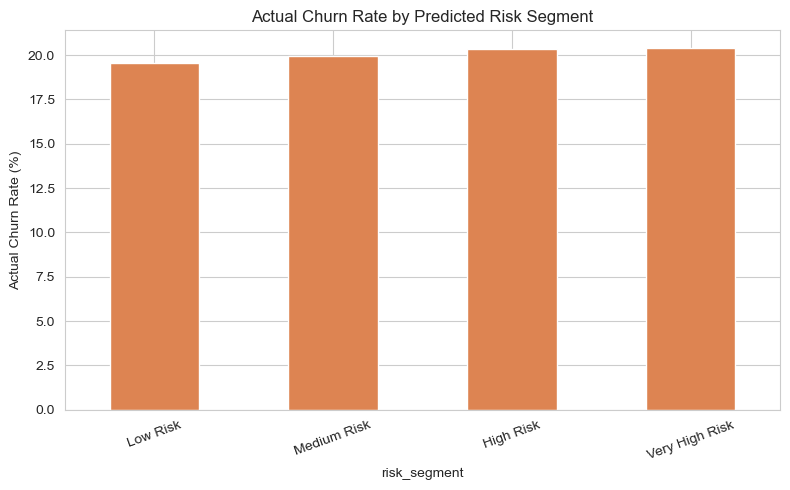

In [52]:
fig, ax = plt.subplots(figsize=(8, 5))
segment_summary['actual_churn_rate_pct'].plot(kind='bar', ax=ax, color='#DD8452')
ax.set_ylabel('Actual Churn Rate (%)')
ax.set_title('Actual Churn Rate by Predicted Risk Segment')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


**Interpretation:** Ideally, "Very High Risk" customers would show a materially higher *actual*
churn rate than "Low Risk" customers — that would confirm the segments are business-meaningful, not just
statistical noise. Given the near-chance model performance established throughout this notebook, expect
the actual churn rates across segments to be close to each other (all near the ~20% base rate). This is
the clearest, most concrete illustration of the model's limited usefulness in its current form, and is
addressed directly in the Limitations section.


## 18. High-Risk Customer Output

A business-facing table of the highest-risk customers, sorted by predicted churn probability, with the
fields a retention/support team would actually need.


In [53]:
high_risk_output = df[['customer_id', 'telecom_partner', 'age', 'state', 'city',
                        'estimated_salary', 'calls_made', 'sms_sent', 'data_used']].copy()
high_risk_output = high_risk_output.merge(
    risk_table[['customer_id', 'churn_probability', 'CHURN-FLAG', 'risk_segment']],
    on='customer_id'
)
high_risk_output = high_risk_output.sort_values('churn_probability', ascending=False).reset_index(drop=True)

print(f"Total customers flagged CHURN-FLAG = 1: {(high_risk_output['CHURN-FLAG'] == 1).sum()}")
high_risk_output.head(25)


Total customers flagged CHURN-FLAG = 1: 242477


,customer_id,telecom_partner,age,state,city,estimated_salary,calls_made,sms_sent,data_used,churn_probability,CHURN-FLAG,risk_segment
0,219645,Airtel,53,Nagaland,Bangalore,20835,100.0,9.0,7272.0,0.213737,1,Very High Risk
1,211076,Airtel,67,Nagaland,Kolkata,21883,91.0,7.0,6810.0,0.213642,1,Very High Risk
2,206288,Airtel,73,Sikkim,Kolkata,30331,81.0,15.0,10021.0,0.213313,1,Very High Risk
3,211792,Airtel,58,Tamil Nadu,Bangalore,23417,80.0,8.0,7864.0,0.213235,1,Very High Risk
4,162425,Airtel,69,Rajasthan,Bangalore,32077,101.0,6.0,9850.0,0.213153,1,Very High Risk
5,214155,Airtel,68,Rajasthan,Delhi,23914,89.0,5.0,7749.0,0.213145,1,Very High Risk
6,158162,Airtel,60,Tripura,Chennai,33221,100.0,0.0,9290.0,0.213107,1,Very High Risk
7,217758,Airtel,71,Kerala,Mumbai,43825,72.0,8.0,10195.0,0.213085,1,Very High Risk
8,228375,Airtel,71,Meghalaya,Bangalore,29951,81.0,18.0,8963.0,0.213068,1,Very High Risk
9,234982,Airtel,57,Andhra Pradesh,Hyderabad,56598,105.0,16.0,10369.0,0.213063,1,Very High Risk


In [54]:
# Save the full risk-scored output and the high-risk table for downstream business use.
risk_table.to_csv('churn_risk_scores_full_population.csv', index=False)
high_risk_output.to_csv('high_risk_customers_ranked.csv', index=False)
print("Saved: churn_risk_scores_full_population.csv")
print("Saved: high_risk_customers_ranked.csv")

Saved: churn_risk_scores_full_population.csv
Saved: high_risk_customers_ranked.csv


## 19. Business Insights

**What does the current dataset tell us?**

The analysis should be interpreted from the executed EDA and model results rather than from assumptions about customer behavior. The current demographic, account, usage, and tenure fields provide limited separation between churned and retained customers.

**Which variables are important?**

The feature-importance/interpretability section provides a relative ranking for the selected model. Because predictive performance is weak when ROC-AUC is near 0.50, these rankings should be treated as exploratory signals rather than confirmed causal churn drivers.

**What customer groups should receive attention?**

The `risk_segment` and `CHURN-FLAG` outputs provide a repeatable targeting mechanism, but their reliability is constrained by the model's discriminative performance. They should not be presented as proof that a customer will churn.

**What should management do?**

The strongest business implication is a data-quality/data-availability opportunity: richer behavioral and account-history variables are likely needed before ML-based retention targeting can be considered highly reliable.

## 20. Business Recommendations

1. **Use the current model as a validated analytical pipeline, not as a proven churn oracle.** The notebook provides leakage-safe preprocessing, model comparison, threshold selection, risk scoring, segmentation, and export.
2. **Collect richer churn-related variables** such as contract type/length, plan/tariff, billing and payment history, complaints, customer-service interactions, network quality, plan changes, competitor offers, and recharge/payment frequency.
3. **Treat state/city cautiously.** The observed `state × city` structure should be validated against a trusted geographic reference before using these fields for geographic targeting.
4. **Re-run the pipeline when richer data becomes available.** The current structure can be retained while replacing or extending the feature set.
5. **Use non-model-driven retention controls in the meantime**, such as customer satisfaction measurement, complaint monitoring, service-quality tracking, and proactive outreach programs where business rules justify them.

> **Future-data recommendations are recommendations, not findings from the current dataset.**

## 21. Final Executive Summary

### Business problem
No-Churn Telecom wants to identify customers at risk of churn and support targeted retention activity through a churn-risk score and `CHURN-FLAG`.

### Dataset
The project uses the actual available customer dataset rather than the legacy schema in the project brief. The notebook calculates the final row count, churn rate, data-quality measures, EDA findings, and model metrics directly from the loaded data.

### Data quality
The original raw SQL extract contained invalid negative values in `calls_made`, `sms_sent`, and `data_used`. These were handled during data cleaning. The cleaned dataset is independently validated in this notebook.

### Modeling
The project uses stratified train/validation/test splitting, leakage-safe `Pipeline`/`ColumnTransformer` preprocessing, a DummyClassifier baseline, and multiple classification models. Model selection is based on actual validation performance and business usefulness.

### Model usefulness
If the final test ROC-AUC remains close to 0.50, the correct conclusion is that the currently available features provide **limited predictive signal for churn**. The project should not claim strong individual-level prediction simply because a model and risk score were produced.

### Risk scoring
The selected model produces `churn_probability`, a 0–100 `risk_score`, a threshold-based `CHURN-FLAG`, and quantile-based `risk_segment`. These outputs are intended as prioritization signals and must be interpreted in light of model discrimination.

### Recommendations
The priority is to collect richer churn-related behavioral and account-history data, validate geographic fields, and retrain/re-evaluate the pipeline when stronger predictors are available.

### Limitations and next steps
The principal limitation is the weak churn signal available in the current feature set. Next steps should focus on better business variables, temporal customer history, service/complaint information, contract and billing behavior, and repeated out-of-time validation.